In [1]:
# Command: Load the training and testing datasets

import pandas as pd
import numpy as np

train_df = pd.read_csv("../train.csv/train.csv")
test_df = pd.read_csv("../test.csv/test.csv")

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

display(train_df.head())

Train shape: (7352, 563)
Test shape: (2947, 563)


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,1,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,1,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,1,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,1,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,1,STANDING


In [2]:
# Command: Separate input features (X) and target variable (y)

# Remove 'subject' because it is only an identifier, not a useful feature
X_train = train_df.drop(["Activity", "subject"], axis=1)
y_train = train_df["Activity"]

X_test = test_df.drop(["Activity", "subject"], axis=1)
y_test = test_df["Activity"]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nTarget classes:")
print(y_train.unique())

X_train shape: (7352, 561)
y_train shape: (7352,)
X_test shape: (2947, 561)
y_test shape: (2947,)

Target classes:
<ArrowStringArray>
[          'STANDING',            'SITTING',             'LAYING',
            'WALKING', 'WALKING_DOWNSTAIRS',   'WALKING_UPSTAIRS']
Length: 6, dtype: str


In [3]:
# Command: Encode the activity labels into numerical values

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(y_train)
y_test = label_encoder.transform(y_test)

print("Encoded classes:")
for i, activity in enumerate(label_encoder.classes_):
    print(i, "→", activity)

print("\nFirst 10 encoded training labels:")
print(y_train[:10])

Encoded classes:
0 → LAYING
1 → SITTING
2 → STANDING
3 → WALKING
4 → WALKING_DOWNSTAIRS
5 → WALKING_UPSTAIRS

First 10 encoded training labels:
[2 2 2 2 2 2 2 2 2 2]


In [4]:
# Command: Scale the training and testing features

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\nFirst 5 scaled values:")
print(X_train[:5, :5])

X_train shape: (7352, 561)
X_test shape: (2947, 561)

First 5 scaled values:
[[ 0.20064157 -0.0636826  -0.41962845 -0.86881389 -0.93944133]
 [ 0.05594788  0.03148567 -0.25390836 -0.87542555 -0.92390168]
 [ 0.07351535 -0.04341648 -0.07629468 -0.86903889 -0.90775954]
 [ 0.06669577 -0.20842166 -0.24971245 -0.87062553 -0.94002248]
 [ 0.03046897  0.02758722 -0.10984784 -0.87518784 -0.93487847]]


In [5]:
# Command: Reshape the data for RNN input

X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (7352, 561, 1)
X_test shape: (2947, 561, 1)


In [6]:
# Command: Build the RNN model

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout

model = Sequential([
    SimpleRNN(64, return_sequences=True, input_shape=(561, 1)),
    Dropout(0.2),

    SimpleRNN(32),
    Dropout(0.2),

    Dense(16, activation="relu"),
    Dense(6, activation="softmax")
])

model.summary()

c:\Users\sharm\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 561, 64)        │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 561, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           102 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,958 (31.09 KB)

 Trainable params: 7,958 (31.09 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Command: Compile the RNN model

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [8]:
# Command: Train the RNN model

from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 26s 254ms/step - accuracy: 0.5378 - loss: 1.1566 - val_accuracy: 0.3610 - val_loss: 1.4223
Epoch 2/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 19s 210ms/step - accuracy: 0.6536 - loss: 0.8116 - val_accuracy: 0.6839 - val_loss: 0.7332
Epoch 3/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 20s 213ms/step - accuracy: 0.7240 - loss: 0.6353 - val_accuracy: 0.7009 - val_loss: 0.6817
Epoch 4/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 20s 212ms/step - accuracy: 0.7490 - loss: 0.5908 - val_accuracy: 0.7322 - val_loss: 0.6382
Epoch 5/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 20s 215ms/step - accuracy: 0.7687 - loss: 0.5433 - val_accuracy: 0.7328 - val_loss: 0.5969
Epoch 6/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 20s 216ms/step - accuracy: 0.7886 - loss: 0.4974 - val_accuracy: 0.7682 - val_loss: 0.5572
Epoch 7/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 20s 214ms/step - accuracy: 0.8038 - loss: 0.4666 - val_accuracy: 0.7791 - val_loss: 0.5369
Epoch 8/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 20s 219ms/step - accuracy: 0.8060 - loss: 0.4617 - val_accu

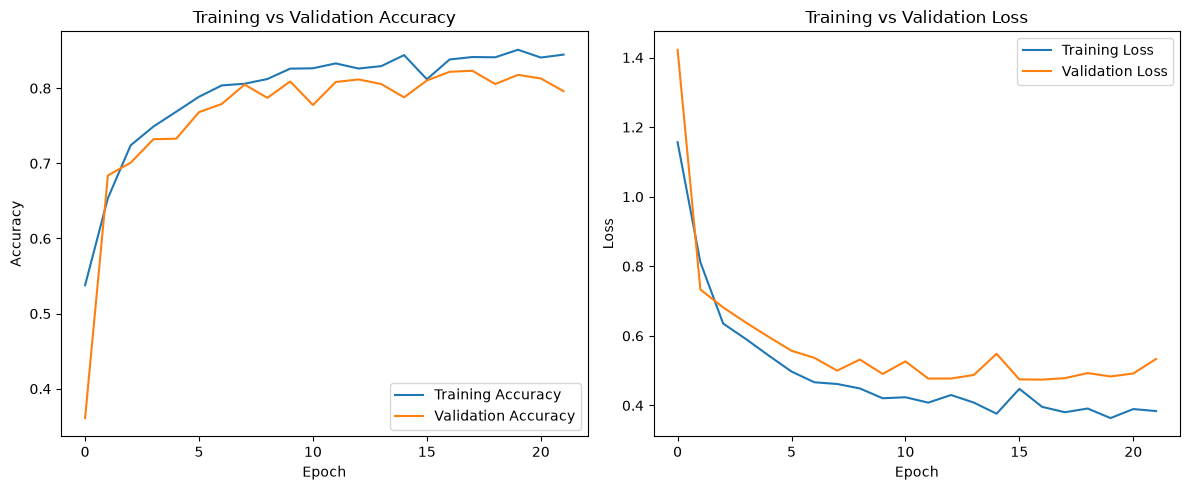

In [10]:
# Command: Import Matplotlib and plot training and validation performance

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [11]:
# Command: Evaluate the RNN model on the test dataset

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\nTest Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

93/93 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.7737 - loss: 0.5764

Test Loss: 0.5763763189315796
Test Accuracy: 0.773668110370636
Test Accuracy (%): 77.3668110370636


93/93 ━━━━━━━━━━━━━━━━━━━━ 6s 60ms/step
Classification Report:

                    precision    recall  f1-score   support

            LAYING       1.00      0.95      0.97       537
           SITTING       0.83      0.83      0.83       491
          STANDING       0.83      0.83      0.83       532
           WALKING       0.63      0.80      0.71       496
WALKING_DOWNSTAIRS       0.61      0.48      0.53       420
  WALKING_UPSTAIRS       0.71      0.69      0.70       471

          accuracy                           0.77      2947
         macro avg       0.77      0.76      0.76      2947
      weighted avg       0.78      0.77      0.77      2947



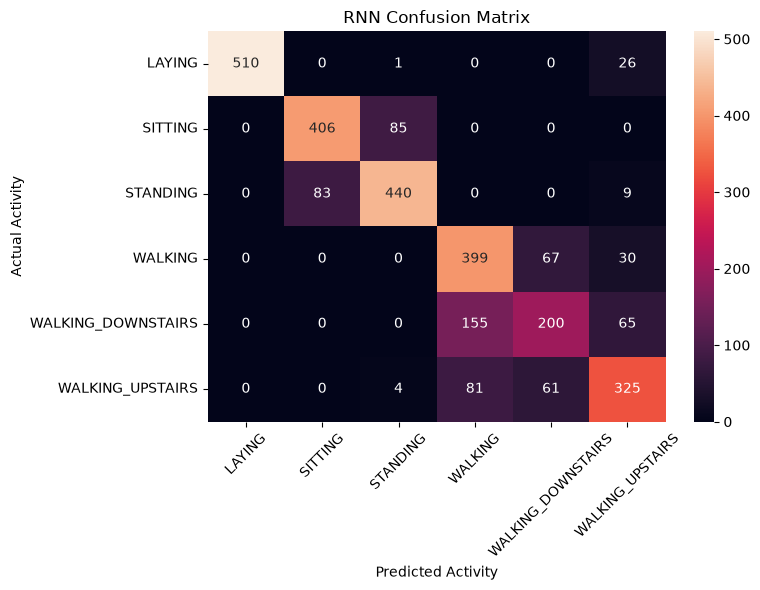

In [12]:
# Command: Generate predictions and evaluate the model

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Predict probabilities
y_pred_prob = model.predict(X_test)

# Convert probabilities into predicted class labels
y_pred = np.argmax(y_pred_prob, axis=1)

# Classification report
print("Classification Report:\n")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_
    )
)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("RNN Confusion Matrix")
plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
# Command: Save the trained RNN model

model.save("rnn_model.keras")

print("RNN model saved successfully!")

RNN model saved successfully!


In [14]:
# Command: Save the scaler and label encoder

import pickle

# Save the scaler
with open("scaler.pkl", "wb") as file:
    pickle.dump(scaler, file)

# Save the label encoder
with open("label_encoder.pkl", "wb") as file:
    pickle.dump(label_encoder, file)

print("Scaler saved successfully!")
print("Label encoder saved successfully!")

Scaler saved successfully!
Label encoder saved successfully!


In [15]:
# Command: Find the saved model and preprocessing files

import os

print("Current folder:")
print(os.getcwd())

print("\nFiles in current folder:")
print(os.listdir())

Current folder:
c:\Users\sharm\OneDrive\Desktop\RNN\rnn.ipynb

Files in current folder:
['label_encoder.pkl', 'rnn.ipynb', 'rnn_model.keras', 'scaler.pkl']
